### 0. Imports

In [1]:
# Fits
from astropy.io import fits

# Math Imports
from scipy.optimize import curve_fit
from scipy.stats import kstest
from astropy.cosmology import FlatLambdaCDM
from astropy.modeling.functional_models import Sersic1D

# Basic Imports
import numpy as np
import matplotlib.pyplot as plt
import json

# Photometry Imports
from photutils.morphology import data_properties
from photutils.aperture import EllipticalAnnulus, EllipticalAperture

#### Data is kept in:
AGNdat_matches.json - AGN images, main properties 

Halpha_main.json - H alpha maps 

Halpha_errs.json - H alpha inverse variances (capped at 10000) 

Main_Image_dict.json - images for matched galaxies

Radial.json - Radial Profiles


### 1. Get List of AGNs

In [2]:
def pull_agn(manga):
    ''' Function to pull important details from MaNGA AGN catalogue, 
    will need to be updated as which details to be used are decided '''
    manga = 'manga-' + manga
    res_row = 0
    with fits.open('manga_agn-v2_0_1.fits') as agn:
        data = agn[1].data
        for i in range(0, 387):
            if manga == data[i][0]:
                res_row = data[i]
                continue
    result = {}
    result['id'] = mcut(res_row[0])              # check the IDs with Marvin as well to see how this works
    result['coords'] = (res_row[1], res_row[2])  # RA and Dec
    result['z'] = res_row[3]                     # Redshifte
    
    # Add details for the fluxes, see paper above
    return result

# As a note on IDs, I think maybe the AGN IDs are observation IDs (plate ifus) not object IDs, this shouldn't make a 
# difference if I load the observation from Marvin but is still worth considering

def mcut(ID):
    ''' just cuts the manga- from an id '''
    stuff = ID.split('-')
    return '-'.join(stuff[1:])
    
def list_IDs(n=387):
    ''' Lists all MaNGA AGN IDs so I can check whenever, n optionally sets how many to list '''
    res = []
    with fits.open('manga_agn-v2_0_1.fits') as agn:
        data = agn[1].data
        for i in range(0, n):
            res.append(mcut(data[i][0]))
    return res

# I'm not filtering based on AGN flags yet, I'm gonna just proccess everything for now and get it later.
def AGN_ids():
    ''' makes a text file of IDs '''
    stuff = list_IDs()
    line = stuff[0]
    for i in range(1, len(stuff)):
        line += ',' + stuff[i]
    with open('AGNifus.txt', 'w') as file:
        file.write(line)
        
def pull_fits():
    ''' opens the AGN file '''
    with fits.open('manga_agn-v2_0_1.fits') as file:
        return file[1].data # ID, RA, DEC, Z, WISE, WISE L, err, BAT, BAT L, err, ...
    # 5, 8, 11, 14 are luminosities, 4, 7, 10, 13 for the ref dict
    
def agn_dict():
    ''' makes reference dict out of the below '''
    stuff = pull_fits()
    res = {}
    for row in stuff:
        res[mcut(row[0])] = row[1:]
    return res

def make_lum(row):
    ''' gets luminosity from the row, if none available returns -1'''
    ls = []
    for j in [4,7,10,13]:
        if not row[j] in [-99.0, 0, 1]:
            ls.append(row[j])
    if len(ls) != 0:
        return np.mean(ls)
    return -1

#### Sciserver 1 -  Get CUBE Fluxes for AGNs

#### Sciserver 2 - Get masses and zs for AGNs

### 2. Process Bolometric Fluxes

In [3]:
# This code is used twice, once to get the sersic index, and later to get the radial SFR
# The big thing is I want to take the index just from higher radii so I don't get wierd values for the distribution

def radial_props(pict, runfit=True):
    ''' Should pull out image properties required for the galaxy - ellipses, re, and n '''
    props = data_properties(np.array(pict))  # Gives ellipticity, orientation, and centroid
    
    finalrad = len(pict)/2  # Keeps from hitting the edge too bad
    width = finalrad/100    # uses 100 slices to find properties
    
    rs = []
    mean_I = []
    tot_F = []
    
    # Producing Radial Profile
    for i in range(1, 101):
        a_out = width*i
        a_in = width*(i-1)
        if i == 1:
            a_in += 0.0001
        rs.append((a_out-a_in)/2 + a_in)     # Assign radius to midpoint of bin instead of far edge
        b_out = a_out*(1-float(props.ellipticity))
        
        # Create Aperture
        sircle = EllipticalAnnulus(props.centroid, a_in=a_in, a_out=a_out, b_out=b_out, theta=props.orientation)
        
        # do photometry
        light = sircle.do_photometry(pict)[0][0] # 00 index is the photometry (1 is the error which ive so far ignored) and the first aperture (there's only one)
        mean_I.append(light/sircle.area)
        if i == 1:
            tot_F.append(light)
        else:
            tot_F.append(light + tot_F[-1])
            
    # Get Halflight Properties
    mid = tot_F[-1]/2
    i = 0
    while tot_F[i+1] < mid:
        i += 1
    re = rs[i] + ((rs[i+1]-rs[i])*(mid-tot_F[i]))/(tot_F[i+1]-tot_F[i])  # Linear interpolation for re
    Ie = mean_I[i] + ((mean_I[i+1]-mean_I[i])*(re-rs[i]))/(rs[i+1]-rs[i])  # Linear interpolation for Ie
    
    if runfit:
        # Use a sersic fit on the rs and Is to get n for the galaxy
        # Set radial bounds
        bottom = re*0.5  # Using half effective radius to avoid the AGN (or bulge too)
        top = min(re*3, max(rs))       # Just cause

        # Find indicies
        low = 0
        high = 0
        while rs[low] < bottom:
            low += 1
            high += 1
        while rs[high] < top:    # low and high are range indicies, both just above respective bound, used for fitting
            high += 1

        # Test function for curve_fit
        def sersicish(r, n):
            return Sersic1D(amplitude=Ie, r_eff=re, n=n)(r)    
        n = curve_fit(sersicish, rs[low:high], mean_I[low:high])[0][0]  # Fit is based just on range given above

        return (props, re, n)
    else:
        return (props, re)

def add_stuff():
    ''' Adds caclulated Sersic Indices to Dictionary '''
    res = {}
    count = 0
    with open('AGNdat.json', 'r') as file:
        res = json.load(file)
    for key in res:
        if not ('my_n' in res[key]):
            props, re, n = radial_props(res[key]['image'])
            res[key]['my_n'] = n
            res[key]['my_re'] = re
            count += 1
    with open('AGNdat.json', 'w') as file:
        json.dump(res, file)
    print(count)

#### Sciserver 3 - Get Matching Galaxies

#### Sciserver 4 - Get Match Images, H alpha maps for AGNs and Matches, H alpha errors for AGNs and Matches

### 3. Process SFRs

In [4]:
H0 = 70  # A temporary assumption
om0 = 0.31  # A general value (?)
spaxel = 0.25

cosmology = FlatLambdaCDM(H0=H0, Om0=om0)

def distance(z):
    ''' calculates the distance from the redshift '''
    return cosmology.luminosity_distance(z).value  # still Mpc
    #v = z * (3e5)   # Assuming z*c=v
    #return v / H0   # distance in Mpc

def SFR(img, z):                                        # https://arxiv.org/html/2603.18498v1
    ''' Returns the SFR map for a galaxy '''
    ha = img*1e-17                               # erg/(s spaxel cm^2), 1e-17 is the factor from the MaNGA values
    # ha *= spaxel                               # erg/(s cm^2)
    d = distance(z) * 3.08567758128E+24          # Mpc -> cm  (https://www.unitconverters.net/length/megaparsec-to-centimeter.htm)
    a = 4 * np.pi * (d**2)                       # Surface Area, cm^2
    L = ha * a                                   # erg/s
    sfr = 7.9e-42 * L                            # Msun / Yr
    lens = cosmology.kpc_proper_per_arcmin(z)/60 # kpc / arcsec, still has units, haven't gotten rid of them cause reasons
    lens = lens.value * 0.5                      # kpc, side length of the pixel
    return sfr / lens**2                         # Msun / (Yr * kpc^2)

### 4. Radial SFRs

In [5]:
def radial(props, re, img, imgerr):
    ''' Makes a radial profile, with errors of a Sigma SFR ''' # errors are variances, with a 100000 clip for 0 values (maybe just leave this?)
    rs = []
    sfr = []
    esfr = []
    # taking annuli
    for i in range(1, 61):
        a_out = 0.025*re*i + 0.5*re       # running from half the halflight out this time, goes out to two and a half Re
        a_in = 0.5*re + 0.025*re*(i-1)
        rs.append((a_out-a_in)/2 + a_in)     # Assign radius to midpoint of bin instead of far edge
        b_out = a_out*(1-float(props.ellipticity))
        # Create Aperture
        sircle = EllipticalAnnulus(props.centroid, a_in=a_in, a_out=a_out, b_out=b_out, theta=props.orientation)
        # do photometry
        light = sircle.do_photometry(img, error=imgerr) # 00 index is the photometry (1 is the error which ive so far ignored) and the first aperture (there's only one)
        sfr.append(light[0][0]/sircle.area)
        esfr.append(light[1][0]/sircle.area)
    return rs, sfr, esfr

# fraction rs is always np.arange(0.5, 2, 0.025)
def make_relsfrs(main='AGNdat_matches.json', halpha='Halpha_main.json', halphae='Halpha_errs.json', imges='Main_Image_dict.json', store='Radial.json'):
    ''' makes a dictionary of all radial profiles for properly matched galaxies and saves it to a JSON file '''
    res = {}
    maindict = {}
    halphadict = {}
    halphaerr = {}
    imgdict = {}
    with open(main, 'r') as file:
        maindict = json.load(file)
    with open(halpha, 'r') as file:
        halphadict = json.load(file)
    with open(imges, 'r') as file:
        imgdict = json.load(file)
    with open(halphae, 'r') as file:
        halphaerr = json.load(file)
    print(len(maindict), len(halphadict), len(halphaerr), len(imgdict))
    count = 0
    for key in maindict:
        if key in halphadict and key in halphaerr and key in imgdict and maindict[key]['matched'] == 1:
            res[key] = {}
            count += 1
            img = maindict[key]['image']
            star = SFR(np.array(halphadict[key]['main']), maindict[key]['z'])
            stare = SFR(np.array(halphaerr[key]['main']), maindict[key]['z'])
            props, re = radial_props(img, runfit=False)
            rs, sfr, esfr = radial(props, re, star, stare)
            res[key]['rs'] = list(rs)
            res[key]['sfr'] = list(sfr)
            res[key]['esfr'] = list(esfr)
            res[key]['matches'] = {}
            for key2 in maindict[key]['matches']:
                res[key]['matches'][key2] = {}
                img = imgdict[key]['matches'][key2]
                star = SFR(np.array(halphadict[key]['matches'][key2]), maindict[key]['matches'][key2]['z'])
                stare = SFR(np.array(halphaerr[key]['matches'][key2]), maindict[key]['matches'][key2]['z'])
                props, re = radial_props(img, runfit=False)
                rs, sfr, esfr = radial(props, re, star, stare)
                res[key]['matches'][key2]['rs'] = list(rs)
                res[key]['matches'][key2]['sfr'] = list(sfr)
                res[key]['matches'][key2]['esfr'] = list(esfr)
            print(count)
    print('final: ', count)
    with open(store, 'w') as file:
        json.dump(res, file)

In [6]:
# Test code to make ellipse plots
if False:
    maindict = {}
    halphadict = {}
    halphaerr = {}
    imgdict = {}
    with open('AGNdat_matches.json', 'r') as file:
        maindict = json.load(file)
    with open('Halpha_main.json', 'r') as file:
        halphadict = json.load(file)
    with open('Middle_Image_dict.json', 'r') as file:
        imgdict = json.load(file)
    with open('Halpha_errs.json', 'r') as file:
        halphaerr = json.load(file)

    for i in range(0, 10):
        print(i)
        key = list(maindict)[i]
        if key in halphadict and key in halphaerr:
            z = maindict[key]['z']
            img = maindict[key]['image']
            star = SFR(np.array(halphadict[key]['main']), z)
            stare = SFR(np.array(halphaerr[key]['main']), z)
            props, re = radial_props(img, runfit=False)
            rs, sfr, esfr = radial(props, re, star, stare)
            print(esfr)
            plt.errorbar(np.arange(0.5, 2, 0.025), sfr, yerr=esfr, c='k', label='SFR')
            plt.yscale('log')
            plt.axvline(0.5, c='r', label='0.5 Halflight Radii')
            plt.axvline(1, c='b', label='1 Halflight Radii')
            plt.axvline(2, c='g', label='2 Halflight Radii')
            plt.xlabel('Radius (In Re)')
            plt.ylabel('SFR in Msun/yr/kpc^2')
            plt.legend()
            plt.show()
            fig, ax = plt.subplots(1,2,figsize=(18,9))
            plt.suptitle('Image and SFR Plot for AGN ' + key)
            im0 = ax[0].imshow(img, cmap='gist_earth')
            im1 = ax[1].imshow(star, cmap='gist_earth')
            ax[0].set_title('Image for ' + key)
            ax[1].set_title('SFR Map for ' + key)
            plt.colorbar(im1, shrink=0.5, label='SFR in Msun/yr/kpc^2')
            plt.colorbar(im0, shrink=0.5, label='Total Flux (Ergs/s)')
            a_out = 0.525*re
            a_in = 0.5*re
            b_out = a_out*(1-float(props.ellipticity))
            sircle = EllipticalAnnulus(props.centroid, a_in=a_in, a_out=a_out, b_out=b_out, theta=props.orientation)
            sircle.plot(ax=ax[0], color='r', label='0.5 Halflight Radii')
            sircle.plot(ax=ax[1], color='r', label='0.5 Halflight Radii')
            a_out = 2*re
            a_in = 1.975*re
            b_out = a_out*(1-float(props.ellipticity))
            sircle = EllipticalAnnulus(props.centroid, a_in=a_in, a_out=a_out, b_out=b_out, theta=props.orientation)
            sircle.plot(ax=ax[0], color='g', label='2 Halflight Radii')
            sircle.plot(ax=ax[1], color='g', label='2 Halflight Radii')
            ax[0].legend()
            ax[1].legend()
            ax[0].set_xlabel('pixels')
            ax[0].set_ylabel('pixels')
            ax[1].set_xlabel('pixels')
            ax[1].set_ylabel('pixels')
            plt.show()

### 5. Profile Analysis

In [18]:
rng = np.random.default_rng()

def quantile(dist, q):
    ''' returns the qth quantile of the distribution
    also makes a bootstrapped error from 50% of the sample and 100 draws '''
    sample = []
    for i in range(0, 100):
        numbers = rng.choice(len(dist), size=int(len(dist)/2))
        numbers = dist[numbers]
        sample.append(np.quantile(numbers, q))
    return [np.mean(sample), np.std(sample)]

def SFRs(conditional, conditional2=None):
    ''' a list of all of the radial sfrs for galaxies satisfying conditional, 
    also returns another list with the matched ones, 
    conditional should take in the ID and the main dict and return whether or not it should be included '''
    props = {}
    with open('AGNdat_matches.json', 'r') as file:
        props = json.load(file)
    SF = {}
    with open('Radial.json', 'r') as file:
        SF = json.load(file)
    sfrs = []
    msfrs = []
    cat = agn_dict()   # just if the conditional is going to require the agn catalogue I only need to load it once
    for key in SF:
        if (conditional2==None) and conditional(key, props, cat):
            sfrs.append(SF[key]['sfr'])
            for key2 in SF[key]['matches']:
                msfrs.append(SF[key]['matches'][key2]['sfr'])
        elif conditional2(key, props, cat) and conditional(key, props, cat):
            sfrs.append(SF[key]['sfr'])
            for key2 in SF[key]['matches']:
                msfrs.append(SF[key]['matches'][key2]['sfr'])
    print(len(sfrs))
    return sfrs, msfrs

def cond_all(a,b,c):
    ''' a conditional for SFRs to return all of them '''
    return True

def step_quantiles(q, conditional=cond_all, conditional2=None):
    ''' returns the quantile SFR for each step, can be filtered '''
    sfrs, msfrs = SFRs(conditional, conditional2=conditional2)
    sfr_quant = []
    msfr_quant = []
    for point in np.transpose(sfrs):
        sfr_quant.append(quantile(point, q))
    for point in np.transpose(msfrs):
        msfr_quant.append(quantile(point, q))   
    return sfr_quant, msfr_quant

In [8]:
# conditionals for the fitting function
def z_filt(side):
    ''' makes z filter '''
    if side == 'low':
        def filt(key, props, a):
            if props[key]['z'] < 0.05:
                return True
            return False
    if side == 'high':
        def filt(key, props, a):
            if props[key]['z'] > 0.085:
                return True
            return False
    return filt

def m_filt(side):
    ''' makes m filter '''
    if side == 'low':
        def filt(key, props, a):
            if props[key]['logmass'] < 10.5:
                return True
            return False
    if side == 'high':
        def filt(key, props, a):
            if props[key]['logmass'] > 11:
                return True
            return False
    return filt

def n_filt(side):
    ''' makes n filter '''
    if side == 'low':
        def filt(key, props, a):
            if props[key]['my_n'] < 2:
                return True
            return False
    if side == 'high':
        def filt(key, props, a):
            if props[key]['my_n'] > 2.5:
                return True
            return False
    return filt

def l_filt(side):
    ''' makes L filter '''
    if side == 'low':
        def filt(key, props, ref):
            if key in ref:
                L = make_lum(ref[key])
                if not L == -1 and L < 44.5:
                    return True
            return False
    if side == 'high':
        def filt(key, props, ref):
            if key in ref:
                L = make_lum(ref[key])
                if not L == -1 and L > 45:
                    return True
            return False
    return filt

In [9]:
# make conditionals based on the distributions to apply to the quantile stuff - filter and check how the quantiles change
# consider plotting on the same plot somehow. 

In [10]:
# overall radial plots
if False:
    q = [0.25, 0.5, 0.75]
    names = ['First Quartile', 'Median', 'Third Quartile']

    fig, ax = plt.subplots(1,3,figsize=(18,6))
    for i in range(0, 3):
        s, ms = step_quantiles(q[i])
        s = np.transpose(s)
        ms = np.transpose(ms)
        ax[i].errorbar(np.arange(0.5, 2, 0.025), s[0], yerr=s[1], color='r', label='AGN Profile')
        ax[i].errorbar(np.arange(0.5, 2, 0.025), ms[0], yerr=ms[1], color='b', label='Matched Galaxies')
        ax[i].set_xlabel('Radius in Halflight Radii')
        ax[i].set_ylabel('SFR per square Kpc (Msun/yr)')
        ax[i].set_title(names[i])
        ax[i].legend()
    plt.show()

In [11]:
# Specific Radii Distributions
if False:  # Picked at 0.75 (10) and 1.5 (40)
    sfrs, msfrs = SFRs(cond_all)
    sfrs, msfrs = np.array(sfrs), np.array(msfrs)
    print(kstest(sfrs[:,10], msfrs[:,10]))
    print(kstest(sfrs[:,40], msfrs[:,40]))
    sfrs, msfrs = np.log10(sfrs), np.log10(msfrs)
    fig, ax = plt.subplots(1,2,figsize=(8,4))
    ax[0].hist(sfrs[:,10], bins=30, range=(-5, 0), density=True, histtype='step', color='r', label='AGN Galaxies', lw=2, cumulative=-1)
    ax[0].hist(msfrs[:,10], bins=30, range=(-5, 0), density=True, histtype='step', color='b', label='Matched Galaxies', lw=2, cumulative=-1)
    ax[1].hist(sfrs[:,40], bins=30, range=(-5, 0), density=True, histtype='step', color='r', label='AGN Galaxies', lw=2, cumulative=-1)
    ax[1].hist(msfrs[:,40], bins=30, range=(-5, 0), density=True, histtype='step', color='b', label='Matched Galaxies', lw=2, cumulative=-1)
    for i in range(0,2):
        ax[i].legend()
        ax[i].set_xlim(0,-5)
        ax[i].set_xlabel('SFR (Msun/yr) per square Kpc')
        ax[i].set_ylabel('P(Sigma SFR < x)')
    ax[0].set_title('At 0.75 Re')
    ax[1].set_title('At 1.5 Re')
    plt.show()

In [12]:
if False:
    fig, ax = plt.subplots(2,2,figsize=(12,12))
    samp = {}
    with open('Radial.json', 'r') as file:
        samp = json.load(file)
    
    dat = {}
    with open('AGNdat_matches.json', 'r') as file:
        dat = json.load(file)
        
    zs = []
    ms = []
    ns = []
    
    for key in samp:
        zs.append(dat[key]['z'])
        ms.append(dat[key]['logmass'])
        ns.append(dat[key]['my_n'])
        
    # Redshift
    ax[0][0].hist(zs, bins=50, range=(0, 0.2), density=True, histtype='step', color='r', label='AGN redshifts', lw=2, cumulative=True)
    ax[0][0].set_xlabel('Redshift')
    ax[0][0].set_ylabel('P(z < x)')
    ax[0][0].set_title('Redshift ('+str(len(zs))+' galaxies)')
    ax[0][0].legend()
    
    # Mass
    ax[0][1].hist(ms, bins=50, range=(8,12), density=True, histtype='step', color='r', label='AGN Masses', lw=2, cumulative=True)
    ax[0][1].set_xlabel('Log Mass (Solar Masses)')
    ax[0][1].set_ylabel('P(log m < x)')
    ax[0][1].set_title('Log Mass ('+str(len(ms))+' galaxies)')
    ax[0][1].legend()
        
    # Index
    ax[1][0].hist(ns, bins=50, range=(0,12), density=True, histtype='step', color='r', label='AGN Sersic Index', lw=2, cumulative=True)
    ax[1][0].set_xlabel('Sersic Index')
    ax[1][0].set_ylabel('P(n < x)')
    ax[1][0].set_title('Sersic Index ('+str(len(ns))+' galaxies)')
    ax[1][0].legend()
    
    # xray luminosity
    agns = pull_fits()
    ids = []
    ref = agn_dict()
    ls = []
    for key in samp:
        valid = []
        for j in [4, 7, 10, 13]:
            if not ref[key][j] in [-99.0, 1, 0]:
                valid.append(ref[key][j])
        if len(valid) != 0:
            ls.append(np.mean(valid))
    ax[1][1].hist(ls, bins=50, density=True, histtype='step', color='r', label='AGN Luminosity', lw=2, cumulative=True)
    ax[1][1].set_xlabel('Bolometric Luminosity (ergs/s)')
    ax[1][1].set_ylabel('P(Log L < x)')
    ax[1][1].set_title('Log Luminosity ('+str(len(ls))+')')
    ax[1][1].legend()
        
    plt.show()

In [13]:
if False:
    fig, ax = plt.subplots(1,4,figsize=(24,6))
    rsfr, regulr = step_quantiles(0.5, cond_all)
    regulr = np.transpose(regulr)
    for i in range(0, 4):
        ax[i].errorbar(np.arange(0.5, 2, 0.025), regulr[0], regulr[1], color='k', label='All Matches', lw=1)
        ax[i].set_xlabel('Radius in Halflight Radii')
        ax[i].set_ylabel('SFR per Kpc (Msun/yr)')
        #ax[i].set_ylim(-3, )
        #ax[i].set_yticks(np.arange(0, 0.05, 0.05/10))
        ax[i].set_yscale('log')

    # Redshift changes
    sfrs, msfrs = step_quantiles(0.5, z_filt('high'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[0].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dashed', label='High z AGNs', lw=1)
    ax[0].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dashed', label='High z Matches', lw=1)

    sfrs, msfrs = step_quantiles(0.5, z_filt('low'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[0].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dotted', label='Low z AGNs', lw=1)
    ax[0].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dotted', label='Low z Matches', lw=1)

    ax[0].legend()

    # Mass changes
    sfrs, msfrs = step_quantiles(0.5, m_filt('high'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[1].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dashed', label='High M AGNs', lw=1)
    ax[1].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dashed', label='High M Matches', lw=1)

    sfrs, msfrs = step_quantiles(0.5, m_filt('low'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[1].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dotted', label='Low M AGNs', lw=1)
    ax[1].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dotted', label='Low M Matches', lw=1)

    ax[1].legend()

    # Sersic changes
    sfrs, msfrs = step_quantiles(0.5, n_filt('high'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[2].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dashed', label='Early Type AGNs', lw=1)
    ax[2].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dashed', label='Early Type Matches', lw=1)

    sfrs, msfrs = step_quantiles(0.5, n_filt('low'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[2].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dotted', label='Late Type AGNs', lw=1)
    ax[2].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dotted', label='Late Type Matches', lw=1)

    ax[2].legend()

    # Luminosity changes
    sfrs, msfrs = step_quantiles(0.5, l_filt('high'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[3].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dashed', label='High L AGNs', lw=1)
    ax[3].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dashed', label='High L Matches', lw=1)

    sfrs, msfrs = step_quantiles(0.5, l_filt('low'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[3].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dotted', label='Low L AGNs', lw=1)
    ax[3].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dotted', label='Low L Matches', lw=1)

    ax[3].legend()

    plt.show()

310
18
74
53
32


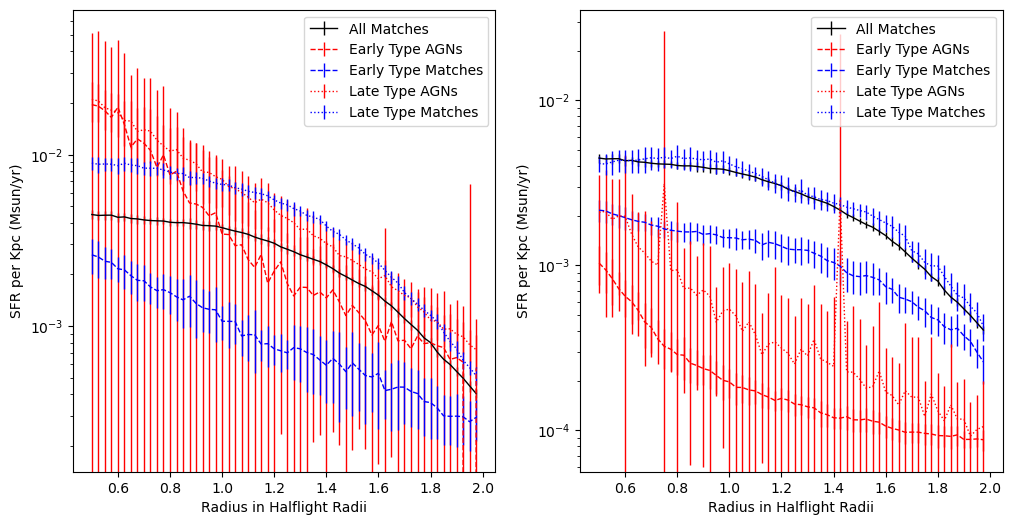

In [20]:
if True:
    fig, ax = plt.subplots(1,2,figsize=(12,6))
    rsfr, regulr = step_quantiles(0.5, cond_all)
    regulr = np.transpose(regulr)
    for i in range(0, 2):
        ax[i].errorbar(np.arange(0.5, 2, 0.025), regulr[0], regulr[1], color='k', label='All Matches', lw=1)
        ax[i].set_xlabel('Radius in Halflight Radii')
        ax[i].set_ylabel('SFR per Kpc (Msun/yr)')
        #ax[i].set_ylim(0, 0.05)
        #ax[i].set_yticks(np.arange(0, 0.05, 0.05/10))
        ax[i].set_yscale('log')
        
    # low luminosity
    sfrs, msfrs = step_quantiles(0.5, n_filt('high'), l_filt('low'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[0].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dashed', label='Early Type AGNs', lw=1)
    ax[0].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dashed', label='Early Type Matches', lw=1)

    sfrs, msfrs = step_quantiles(0.5, n_filt('low'), l_filt('low'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[0].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dotted', label='Late Type AGNs', lw=1)
    ax[0].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dotted', label='Late Type Matches', lw=1)
    
    ax[0].legend()
    
    # low luminosity
    sfrs, msfrs = step_quantiles(0.5, n_filt('high'), l_filt('high'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[1].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dashed', label='Early Type AGNs', lw=1)
    ax[1].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dashed', label='Early Type Matches', lw=1)

    sfrs, msfrs = step_quantiles(0.5, n_filt('low'), l_filt('high'))
    sfrs, msfrs = np.transpose(sfrs), np.transpose(msfrs)
    ax[1].errorbar(np.arange(0.5, 2, 0.025), sfrs[0], sfrs[1], color='r', ls='dotted', label='Late Type AGNs', lw=1)
    ax[1].errorbar(np.arange(0.5, 2, 0.025), msfrs[0], msfrs[1], color='b', ls='dotted', label='Late Type Matches', lw=1)
    
    ax[1].legend()
    
    plt.show()